# 03 — PSO Wavelet Denoising

Jurnal menyebut pencarian parameter wavelet dengan PSO, termasuk basis wavelet, hard/soft threshold, level dekomposisi, aturan threshold, dan rescaling. Detail fungsi objektif PSO tidak dijelaskan lengkap dalam ringkasan metode yang tersedia.

Karena itu, notebook ini menyediakan **implementasi PSO-WT yang dapat dijalankan** dengan fungsi objektif SURE (Stein's Unbiased Risk Estimate) pada koefisien detail. Ini adalah pilihan implementasi yang harus ditulis sebagai keputusan metodologi, bukan diklaim identik 100% dengan kode penulis jurnal.

AWGN 10 dB disediakan sebagai opsi eksperimen. Untuk data ECG nyata, jangan menambahkan noise secara default kecuali memang ingin mereplikasi skenario noise jurnal.

In [1]:
from pathlib import Path
import os, json, pickle, warnings
import numpy as np
import pandas as pd

ROOT = Path("..") if Path("..").exists() else Path(".")
DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
WORK_DIR = DATA_DIR / "processed"
WORK_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

CLASS_NAMES = ["CHF", "NSR"]
FS_TARGET = 128
RECORD_LENGTH = 65536
WINDOW_LENGTH = 3136
HOP_LENGTH = 784

import pywt
from pathlib import Path

IN_DIR = WORK_DIR / "02_preprocessed"
IN_MANIFEST = IN_DIR / "manifest_preprocessed.csv"
OUT_DIR = WORK_DIR / "03_denoised"
OUT_DIR.mkdir(parents=True, exist_ok=True)

ADD_AWGN = False       # ubah True untuk eksperimen AWGN 10 dB
AWGN_SNR_DB = 10
PSO_RECORDS = 3        # jumlah rekaman contoh untuk mencari konfigurasi global
N_PARTICLES = 8
N_ITER = 10
WAVELETS = ["coif1", "sym4", "db4", "bior2.2"]
THRESHOLD_TYPES = ["soft", "hard"]

In [2]:
def add_awgn(x, snr_db, rng):
    x = np.asarray(x, dtype=np.float64)
    power = np.mean(x**2)
    if power <= 0:
        return x.astype(np.float32)
    noise_power = power / (10**(snr_db/10))
    noise = rng.normal(0, np.sqrt(noise_power), size=x.shape)
    return (x + noise).astype(np.float32)

def sure_threshold(detail, sigma):
    y = np.asarray(detail, dtype=np.float64).ravel() / (sigma + 1e-12)
    n = y.size
    if n == 0:
        return 0.0
    absolute_values = np.sort(np.abs(y))
    counts = np.arange(1, n + 1, dtype=np.float64)
    cumulative_squares = np.cumsum(absolute_values ** 2)
    risks = (n - 2 * counts + cumulative_squares
             + (n - counts) * absolute_values ** 2)
    return float(np.sqrt(max(0.0, np.min(risks))) * sigma)

def wavelet_denoise(x, wavelet="db4", level=5, threshold_type="soft"):
    coeffs = pywt.wavedec(x, wavelet, level=level, mode="symmetric")
    # Estimasi sigma dari koefisien detail level tertinggi (cD1)
    finest_detail = coeffs[-1]
    sigma = np.median(np.abs(finest_detail - np.median(finest_detail))) / 0.6745
    sigma = max(float(sigma), 1e-8)
    new_coeffs = [coeffs[0]]
    for detail in coeffs[1:]:
        thr = sure_threshold(detail, sigma)
        new_coeffs.append(pywt.threshold(detail, thr, mode=threshold_type))
    y = pywt.waverec(new_coeffs, wavelet, mode="symmetric")
    return y[:len(x)].astype(np.float32)

def config_objective(x, wavelet, level, threshold_type):
    # SURE total yang dinormalisasi; semakin kecil dianggap semakin baik.
    coeffs = pywt.wavedec(x, wavelet, level=level, mode="symmetric")
    d = np.concatenate([c.ravel() for c in coeffs[1:]])
    sigma = np.median(np.abs(coeffs[-1] - np.median(coeffs[-1]))) / 0.6745
    sigma = max(float(sigma), 1e-8)
    return sum((sure_threshold(c, sigma)/(sigma+1e-12))**2 for c in coeffs[1:]) / max(1, len(coeffs)-1)

In [3]:
manifest = pd.read_csv(IN_MANIFEST)
manifest = manifest[manifest["label"].isin(CLASS_NAMES)].reset_index(drop=True)
if set(manifest["label"]) != set(CLASS_NAMES):
    raise ValueError(f"Manifest denoising harus berisi CHF dan NSR; ditemukan: {sorted(set(manifest['label']))}")
sample_rows = manifest.head(min(PSO_RECORDS, len(manifest)))
sample_signals = [np.load(p).astype(np.float32) for p in sample_rows["path"]]

# PSO kontinu yang memetakan posisi ke indeks parameter diskrit.
# Dimensi: wavelet, level, threshold type.
rng = np.random.default_rng(RANDOM_STATE)
bounds_low = np.array([0, 1, 0], dtype=float)
bounds_high = np.array([len(WAVELETS)-1, 10, len(THRESHOLD_TYPES)-1], dtype=float)

def decode(pos):
    wi = int(np.clip(np.rint(pos[0]), 0, len(WAVELETS)-1))
    lev = int(np.clip(np.rint(pos[1]), 1, 10))
    ti = int(np.clip(np.rint(pos[2]), 0, len(THRESHOLD_TYPES)-1))
    return WAVELETS[wi], lev, THRESHOLD_TYPES[ti]

def fitness(pos):
    w, lev, th = decode(pos)
    vals = []
    for x in sample_signals:
        max_level = pywt.dwt_max_level(len(x), pywt.Wavelet(w).dec_len)
        lev_use = max(1, min(lev, max_level))
        vals.append(config_objective(x, w, lev_use, th))
    return float(np.mean(vals))

n_dim = 3
pos = rng.uniform(bounds_low, bounds_high, size=(N_PARTICLES, n_dim))
vel = np.zeros_like(pos)
pbest = pos.copy()
pbest_fit = np.array([fitness(p) for p in pos])
gbest_idx = int(np.argmin(pbest_fit))
gbest, gbest_fit = pbest[gbest_idx].copy(), pbest_fit[gbest_idx]
w_inertia, c1, c2 = 0.7, 1.4, 1.4

for it in range(N_ITER):
    r1, r2 = rng.random(pos.shape), rng.random(pos.shape)
    vel = w_inertia*vel + c1*r1*(pbest-pos) + c2*r2*(gbest-pos)
    pos = np.clip(pos+vel, bounds_low, bounds_high)
    fits = np.array([fitness(p) for p in pos])
    improved = fits < pbest_fit
    pbest[improved], pbest_fit[improved] = pos[improved], fits[improved]
    idx = int(np.argmin(pbest_fit))
    if pbest_fit[idx] < gbest_fit:
        gbest, gbest_fit = pbest[idx].copy(), pbest_fit[idx]
    print(f"Iterasi {it+1}/{N_ITER} | best objective={gbest_fit:.6f}")

best_wavelet, best_level, best_threshold = decode(gbest)
best_level = min(best_level, pywt.dwt_max_level(RECORD_LENGTH, pywt.Wavelet(best_wavelet).dec_len))
pso_config = {"wavelet": best_wavelet, "level": int(best_level),
              "threshold_type": best_threshold, "objective": float(gbest_fit),
              "objective_method": "mean SURE on wavelet detail coefficients"}
print("Konfigurasi terpilih:", pso_config)
with open(OUT_DIR / "pso_wavelet_config.json", "w") as f:
    json.dump(pso_config, f, indent=2)

Iterasi 1/10 | best objective=3763.222901
Iterasi 2/10 | best objective=3763.222901
Iterasi 3/10 | best objective=3763.222901
Iterasi 4/10 | best objective=3763.222901
Iterasi 5/10 | best objective=3763.222901
Iterasi 6/10 | best objective=3763.222901
Iterasi 7/10 | best objective=3763.222901
Iterasi 8/10 | best objective=3763.222901
Iterasi 9/10 | best objective=3763.222901
Iterasi 10/10 | best objective=3763.222901
Konfigurasi terpilih: {'wavelet': 'sym4', 'level': 10, 'threshold_type': 'hard', 'objective': 3763.2229008230847, 'objective_method': 'mean SURE on wavelet detail coefficients'}


In [4]:
rng = np.random.default_rng(RANDOM_STATE)
for _, row in manifest.iterrows():
    x = np.load(row["path"]).astype(np.float32)
    xin = add_awgn(x, AWGN_SNR_DB, rng) if ADD_AWGN else x
    lev = min(best_level, pywt.dwt_max_level(len(xin), pywt.Wavelet(best_wavelet).dec_len))
    y = wavelet_denoise(xin, best_wavelet, lev, best_threshold)
    np.save(OUT_DIR / f"{row['record_id']}.npy", y)
manifest_out = manifest.copy()
manifest_out["path"] = manifest_out["record_id"].apply(lambda rid: str((OUT_DIR/f"{rid}.npy").resolve()))
manifest_out.to_csv(OUT_DIR / "manifest_denoised.csv", index=False)
print("Sinyal denoised tersimpan:", OUT_DIR.resolve())

Sinyal denoised tersimpan: C:\Users\LENOVO\Downloads\ECG_2D_CNN_Project_Dataset_AutoDownload\ECG_2D_CNN_Project\data\processed\03_denoised


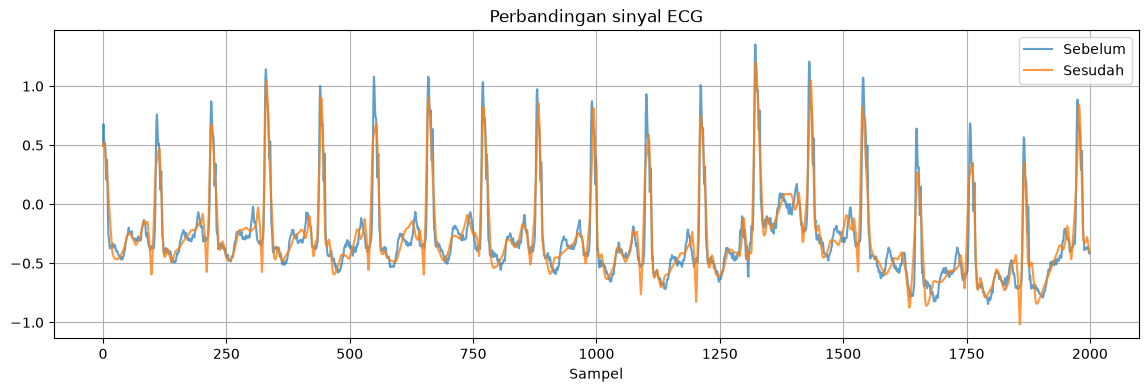

In [5]:
row = manifest.iloc[0]
original = np.load(row["path"])
denoised = np.load(OUT_DIR / f"{row['record_id']}.npy")
n = min(2000, len(original))
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 4))
plt.plot(original[:n], label="Sebelum", alpha=.7)
plt.plot(denoised[:n], label="Sesudah", alpha=.8)
plt.legend(); plt.title("Perbandingan sinyal ECG"); plt.xlabel("Sampel"); plt.grid(True); plt.show()

**Penting:** PSO di sini mencari konfigurasi global dari beberapa rekaman contoh, lalu konfigurasi yang sama diterapkan ke seluruh data. Simpan konfigurasi dan seed agar eksperimen dapat diulang. Jangan memakai hasil ini sebagai bukti bahwa sinyal klinis sudah bebas artefak.